# C02w — Adaptive camouflage with all 54 completed texts
Run in a fresh kernel. Reads the original 27 plus the newly completed 27 from `C02w_adaptive_camouflage_v1/final_texts_54.csv`. Preserves the existing 20/34 split and original texts. No generation, repair, or five-case pilot outputs are substituted. Fits the existing adaptation comparisons and evaluates on the 34 adaptation-held-out sources. These sources were used in earlier discovery diagnostics; this is not a fresh independent test set.


In [1]:
# Export every figure to reproduction/figures as well as the run directory.
from pathlib import Path as _FigurePath
def _export_figure(figure, filename, *args, **kwargs):
    original = _FigurePath(filename)
    original.parent.mkdir(parents=True, exist_ok=True)
    figure.savefig(original, *args, **kwargs)
    figure_dir = ROOT / "figures"
    figure_dir.mkdir(parents=True, exist_ok=True)
    try:
        suffix = original.relative_to(OUT).with_suffix("").as_posix().replace("/", "_")
    except ValueError:
        suffix = original.stem
    target = figure_dir / ("C02w_" + suffix + original.suffix)
    figure.savefig(target, *args, **kwargs)

from pathlib import Path
import json,hashlib,os,pickle,re
from collections import Counter
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy,textstat,sklearn
from sklearn.base import clone
from sklearn.metrics import roc_auc_score,roc_curve,auc
from IPython.display import display
ROOT=Path.cwd() if (Path.cwd()/'results').exists() else Path.cwd().parent
assert (ROOT/'results').exists()
BASE=ROOT/'results/causal/C02d2_fz118_ghostbuster_raid'
PRIOR=ROOT/'results/causal/C02e2_raid_feature_guided'
PARENT=ROOT/'results/causal/C02r_discovery_gated_punctuation'
PREV=ROOT/'results/causal/C02s_relative_likelihood_sensitivity'
LATEST=PREV/'wps_repair_v1/downstream_v1/hyphen_repair_v1/texts.csv'
INPUT_DIR=ROOT/'results/causal/C02w_adaptive_camouflage_v1'
INPUT=INPUT_DIR/'final_texts_54.csv'
OUT=ROOT/'results/causal/C02w_adaptive_camouflage_scored54_v1';OUT.mkdir(exist_ok=True,parents=True)
SEED=20260909;B=2000;BUDGETS=[.01,.05,.10,.20]
normalize=lambda t:str(t).replace('\n',' ').replace('\r',' ')
def sha(p):return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def atomic(p,obj):
    p=Path(p);tmp=p.with_suffix('.tmp');tmp.write_text(json.dumps(obj,indent=2,ensure_ascii=False,allow_nan=False));os.replace(tmp,p)
def freeze(p,obj):
    if p.exists():assert json.loads(p.read_text())==obj,f'Changed contract: use new output version: {p}'
    else:atomic(p,obj)
selection=pd.read_csv(PARENT/'selection.csv')
selection=selection.loc[selection.partition.eq('discovery')].sort_values('case_id').reset_index(drop=True)
assert len(selection)==54 and selection.case_id.is_unique and selection.source_id.is_unique
# Largest-remainder genre allocation; fixed seed shuffles only within genre.
counts=selection.domain.value_counts().sort_index();quota=counts*20/54
allocation=np.floor(quota).astype(int)
for g in sorted(counts.index,key=lambda g:(-(quota[g]-allocation[g]),g))[:20-int(allocation.sum())]:allocation[g]+=1
rng=np.random.default_rng(SEED);adapt=[]
for g in counts.index:
    ids=selection.loc[selection.domain.eq(g),'case_id'].to_numpy().copy();rng.shuffle(ids);adapt.extend(ids[:allocation[g]])
selection['role']=np.where(selection.case_id.isin(adapt),'adaptation','test')
assert sum(selection.role.eq('adaptation'))==20 and sum(selection.role.eq('test'))==34
# Verify the same split used when preparing the 54 texts.
prior_split=json.loads((INPUT_DIR/'split.json').read_text())
split_contract=dict(seed=SEED,selection_sha=sha(PARENT/'selection.csv'),rows=selection[['case_id','source_id','domain','role']].to_dict('records'))
assert prior_split==split_contract,'Existing 20/34 split differs'
freeze(OUT/'split.json',split_contract)
selection.to_csv(OUT/'split.csv',index=False)
latest=pd.read_csv(LATEST,keep_default_na=False)
assert latest.case_id.is_unique and len(latest)==27
assert set(latest.case_id)<=set(selection.case_id)
known=latest.set_index('case_id').text.to_dict()
assert INPUT.exists(),f'Completed 54-text file missing: {INPUT}'
print('Reading completed texts:',INPUT)


Reading completed texts: ../results/causal/C02w_adaptive_camouflage_v1/final_texts_54.csv


## Validate the completed 54-text input
Completion means all stages ran, regardless of target attainment. All 54 cases remain included.


In [2]:
data=pd.read_csv(INPUT,keep_default_na=False)
assert data.case_id.is_unique and set(data.case_id)==set(selection.case_id)
data=data.set_index('case_id').loc[selection.case_id].reset_index()
assert data.source_id.tolist()==selection.source_id.tolist() and data.domain.tolist()==selection.domain.tolist()
missing=data.loc[~data.pipeline_status.eq('complete')|data.text.str.strip().eq('')|data.provenance.str.strip().eq('')]
if len(missing):
    display(missing[['case_id','domain','pipeline_status']])
    raise RuntimeError(f'{len(missing)} final outputs still missing. Complete their frozen pipeline first; no detector has been fitted.')
for cid,t in known.items():assert data.set_index('case_id').loc[cid,'text']==t,f'Existing output changed: {cid}'
data['batch']=np.where(data.case_id.isin(known),'Original 27','New 27')
assert data.groupby('batch').size().eq(27).all()
coverage=data[['case_id','source_id','domain','batch','pipeline_status','provenance']].copy()
coverage['role']=selection.role.to_numpy()
coverage.to_csv(OUT/'coverage.csv',index=False)
display(pd.crosstab(coverage.batch,coverage.role))
print('Loaded all 54 completed texts: 27 original + 27 new; 20 adaptation + 34 test.')
# Hash the actual downstream checkpoints referenced by the completed CSV.
provenance_paths=sorted({ROOT / value for value in data.provenance},key=str)
for path in provenance_paths:assert path.is_file(),f'Missing provenance file: {path}'
features=pd.read_parquet(BASE/'fz118_paired_features.parquet')
corpus=pd.read_parquet(BASE/'paired_corpus.parquet')
assert features.source_id.is_unique and corpus.source_id.is_unique
text_map=corpus.set_index('source_id').text.to_dict()
# All AI source originals must be held out from original training.
source_rows=features.set_index('source_id').loc[data.source_id]
assert source_rows.label.eq(1).all() and source_rows.dataset.eq('raid').all()
train=features.loc[features.dataset.eq('raid')&features.split.eq('train')].copy()
assert set(data.source_id).isdisjoint(train.source_id)
ordinary={}
for r in selection.itertuples():
    p=PREV/r.case_id/'ordinary/state.json';state=json.loads(p.read_text())['state']
    assert state['status']=='completed_eos',f'Ordinary control incomplete: {r.case_id}'
    ordinary[r.case_id]=normalize(state['committed_text'])
# Exact normalized text overlap is also forbidden across fit/calibration/test roles.
def th(t):return hashlib.sha256(normalize(t).strip().encode()).hexdigest()
data['text_hash']=data.text.map(th);assert data.text_hash.is_unique
train_hash={th(text_map[s]) for s in train.source_id}
assert set(data.text_hash).isdisjoint(train_hash)
ai_adapt=selection.role.eq('adaptation').to_numpy();ai_test=~ai_adapt
assert {th(ordinary[c]) for c in selection.case_id}.isdisjoint(train_hash)
assert {th(ordinary[c]) for c in selection.loc[ai_adapt,'case_id']}.isdisjoint({th(ordinary[c]) for c in selection.loc[ai_test,'case_id']})
assert {th(ordinary[c]) for c in selection.loc[ai_adapt,'case_id']}.isdisjoint(set(data.loc[ai_test,'text_hash']))
nlp=spacy.load('en_core_web_sm')
contract_paths=[INPUT,PARENT/'selection.csv',LATEST,BASE/'fz118_paired_features.parquet',BASE/'paired_corpus.parquet',BASE/'google-10000-english.txt',BASE/'fz118_feature_contract.json',PRIOR/'fz118_raid_model_features.json',PRIOR/'fz118_raid_no_parentheses_detector.pkl']
contract_paths += provenance_paths
contract_paths += [PREV/c/'ordinary/state.json' for c in selection.case_id]
nb=ROOT/'experiments/C02w_adaptive_camouflage.ipynb'
code_hash=hashlib.sha256(json.dumps([c['source'] for c in json.loads(nb.read_text())['cells'] if c['cell_type']=='code']).encode()).hexdigest()
freeze(OUT/'contract.json',dict(inputs={str(p.relative_to(ROOT)):sha(p) for p in contract_paths},code_hash=code_hash,seed=SEED,
    sklearn=sklearn.__version__,spacy=nlp.meta,augmentation_weight=1,bootstraps=B,budgets=BUDGETS))


role,adaptation,test
batch,,
New 27,12,15
Original 27,8,19


Loaded all 54 completed texts: 27 original + 27 new; 20 adaptation + 34 test.


In [3]:
import re, pickle
from collections import Counter
import textstat
PUNCTUATION = [('comma', ','), ('period', '.'), ('colon', ':'), ('semicolon', ';'),
    ('question', '?'), ('exclamation', '!'), ('hyphen', '-'), ('quote', '"'),
    ('lparen', '('), ('rparen', ')'), ('lbracket', '['), ('rbracket', ']'), ('newline', '\n')]
google_words=[w.strip().lower() for w in (BASE/'google-10000-english.txt').read_text().splitlines() if w.strip()]
GOOGLE_TOP={n:set(google_words[:n]) for n in [100,1000,10000]}

def safe_div(a, b):
    return float(a) / float(b) if b else 0.0


def clean_word_tokens(span):
    return [
        token.text.lower()
        for token in span
        if token.is_alpha
    ]


def clean_pos_tokens(span):
    return [
        token.pos_
        for token in span
        if token.is_alpha
    ]


def ngram_counter(sequence, n):
    if len(sequence) < n:
        return Counter()
    return Counter(
        tuple(sequence[i:i+n])
        for i in range(len(sequence) - n + 1)
    )


def multiset_overlap(left, right, n):
    a = ngram_counter(left, n)
    b = ngram_counter(right, n)
    denominator = min(sum(a.values()), sum(b.values()))
    if denominator == 0:
        return 0.0
    shared = sum((a & b).values())
    return float(shared / denominator)


def overlap_histogram(sentences, token_fn, n):
    if len(sentences) < 2:
        return np.zeros(10, dtype=np.float64)

    values = [
        multiset_overlap(token_fn(left), token_fn(right), n)
        for left, right in zip(sentences[:-1], sentences[1:])
    ]

    # Include 1.0 in the final bin.
    bins = np.minimum((np.asarray(values) * 10).astype(int), 9)
    counts = np.bincount(bins, minlength=10).astype(np.float64)
    return counts / max(1, len(values))


def conjunction_overlap(sentences, n):
    values = []
    for sentence in sentences:
        words = clean_word_tokens(sentence)
        for i, word in enumerate(words):
            if word == "and":
                values.append(
                    multiset_overlap(words[:i], words[i+1:], n)
                )
    return float(np.mean(values)) if values else 0.0


def punctuation_count(text, symbol_name, symbol):
    if symbol_name == "quote":
        return text.count('"') + text.count("“") + text.count("”")
    return text.count(symbol)


def finite_readability(fn, text):
    try:
        value = float(fn(text))
        return value if np.isfinite(value) else 0.0
    except Exception:
        return 0.0


def extract_fz118(text):
    text = str(text)
    doc = nlp(text)
    sentences = [sent for sent in doc.sents if clean_word_tokens(sent)]
    words = [token.text.lower() for token in doc if token.is_alpha]

    n_characters = len(text)
    n_words = len(words)
    n_sentences = len(sentences)
    n_syllables = int(textstat.syllable_count(text))
    n_difficult = int(textstat.difficult_words(text))
    n_short = sum(len(word) <= 3 for word in words)
    n_long = sum(len(word) >= 7 for word in words)

    values = [
        n_characters,
        n_syllables,
        n_words,
        n_sentences,
        n_difficult,
        n_short,
        n_long,
        safe_div(n_characters, n_words),
        safe_div(n_syllables, n_words),
        safe_div(n_words, n_sentences),
        safe_div(n_difficult, n_words),
        safe_div(n_short, n_words),
        safe_div(n_long, n_words),
        finite_readability(textstat.automated_readability_index, text),
        finite_readability(textstat.coleman_liau_index, text),
        finite_readability(textstat.flesch_kincaid_grade, text),
        finite_readability(textstat.flesch_reading_ease, text),
        finite_readability(textstat.gunning_fog, text),
        finite_readability(textstat.lix, text),
        finite_readability(textstat.mcalpine_eflaw, text),
        finite_readability(textstat.rix, text),
        finite_readability(textstat.smog_index, text),
        safe_div(sum(token.is_stop for token in doc if token.is_alpha), n_words),
        safe_div(len(set(words)), n_words),
        safe_div(sum(word in GOOGLE_TOP[100] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[1000] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[10000] for word in words), n_words),
    ]

    punct_counts = [
        punctuation_count(text, name, symbol)
        for name, symbol in PUNCTUATION
    ]
    values += [safe_div(count, n_characters) for count in punct_counts]
    values += [safe_div(count, n_sentences) for count in punct_counts]

    paragraphs = [p.strip() for p in re.split(r"\n\s*\n", text) if p.strip()]
    paragraph_word_counts = [
        sum(token.is_alpha for token in nlp.make_doc(paragraph))
        for paragraph in paragraphs
    ]
    values += [
        len(paragraphs),
        float(np.mean(paragraph_word_counts)) if paragraph_word_counts else 0.0,
    ]

    for token_fn in [clean_word_tokens, clean_pos_tokens]:
        for n in [1, 2, 3]:
            values += overlap_histogram(sentences, token_fn, n).tolist()

    values += [conjunction_overlap(sentences, n) for n in [1, 2, 3]]

    vector = np.asarray(values, dtype=np.float64)
    assert vector.shape == (118,)
    assert np.isfinite(vector).all()
    return vector
# Exact tree-path contributions, summed across the frozen forest.
FEATURE_NAMES=json.loads((BASE/'fz118_feature_contract.json').read_text())['feature_names']
model_features=json.loads((PRIOR/'fz118_raid_model_features.json').read_text())
with (PRIOR/'fz118_raid_no_parentheses_detector.pkl').open('rb') as f:detector=pickle.load(f)
assert list(detector.classes_)==[0,1]
def contributions(X):
    a=np.asarray(X,dtype=np.float32); output=np.zeros_like(a,dtype=float);bias=0.
    for estimator in detector.estimators_:
        tree=estimator.tree_; value=tree.value[:,0,:].astype(float)
        prob=value[:,1]/value.sum(axis=1);bias+=prob[0]/len(detector.estimators_)
        for i,row in enumerate(a):
            node=0
            while tree.children_left[node]!=tree.children_right[node]:
                feature=tree.feature[node]
                child=tree.children_left[node] if row[feature]<=tree.threshold[node] else tree.children_right[node]
                output[i,feature]+=(prob[child]-prob[node])/len(detector.estimators_)
                node=child
    assert np.allclose(bias+output.sum(axis=1),detector.predict_proba(X)[:,1],atol=1e-8)
    return output


@lru_cache(maxsize=8192)
def vector_for(text): return extract_fz118(normalize(text))
def frame_for(texts):
    return pd.DataFrame([vector_for(t) for t in texts],columns=FEATURE_NAMES)


In [4]:
assert len(model_features)==114 and len(FEATURE_NAMES)==118
assert detector.get_params()['n_estimators']==600
Xbase=train[model_features].astype(float);ybase=train.label.astype(int)
# Check extractor compatibility on original AI texts before measuring rewritten ones.
for r in data.itertuples():
    np.testing.assert_allclose(extract_fz118(normalize(text_map[r.source_id])),features.set_index('source_id').loc[r.source_id,FEATURE_NAMES].to_numpy(float),atol=1e-9,rtol=0)
Xrewrite=frame_for(data.text.tolist())[model_features]
Xordinary=frame_for([ordinary[c] for c in data.case_id])[model_features]
Xrewrite.assign(case_id=data.case_id.to_numpy()).to_csv(OUT/'rewritten_features.csv',index=False)
# Validation humans calibrate; test humans evaluate. No random split of previously trained humans.
hcal=features.loc[features.dataset.eq('raid')&features.split.eq('validation')&features.label.eq(0)].copy()
htest=features.loc[features.dataset.eq('raid')&features.split.eq('test')&features.label.eq(0)].copy()
assert len(hcal)>0 and len(htest)>0
for h in [hcal,htest]:assert set(h.source_id).isdisjoint(train.source_id)
assert set(hcal.source_id).isdisjoint(htest.source_id)
assert {th(text_map[s]) for s in hcal.source_id}.isdisjoint({th(text_map[s]) for s in htest.source_id})
for h in [hcal,htest]:assert {th(text_map[s]) for s in h.source_id}.isdisjoint(train_hash|set(data.text_hash))
mix=selection.loc[ai_test,'domain'].value_counts(normalize=True)
def human_subset(h):
    h=h.loc[h.domain.isin(mix.index)].copy();counts=h.domain.value_counts()
    assert set(mix.index)<=set(counts.index),'Missing human genre'
    h['weight']=[mix[g]/counts[g] for g in h.domain];return h
hcal=human_subset(hcal);htest=human_subset(htest)
hcal[['source_id','domain','weight']].to_csv(OUT/'human_calibration_manifest.csv',index=False)
htest[['source_id','domain','weight']].to_csv(OUT/'human_test_manifest.csv',index=False)
models={'Frozen':detector}
for name,extra in [('Base refit',None),('Adapted rewritten',Xrewrite.loc[ai_adapt]),('Ordinary augmentation',Xordinary.loc[ai_adapt])]:
    m=clone(detector)
    assert m.random_state is not None,'Freeze estimator seed before adaptation'
    X=Xbase if extra is None else pd.concat([Xbase,extra],ignore_index=True)
    y=ybase if extra is None else pd.concat([ybase,pd.Series(np.ones(len(extra),dtype=int))],ignore_index=True)
    m.fit(X,y);models[name]=m
    with (OUT/(name.lower().replace(' ','_')+'.pkl')).open('wb') as f:pickle.dump(m,f)
# Exact replay is a required gate, not an assumed equivalence.
check=pd.concat([Xbase,Xrewrite],ignore_index=True)
np.testing.assert_allclose(models['Base refit'].predict_proba(check),detector.predict_proba(check),atol=1e-12,rtol=0,
    err_msg='Base training replay differs from frozen detector. Resolve provenance/version before interpreting adaptation.')
print('Original training replay verified. Adaptation uses exactly 20 rewritten examples.')


Original training replay verified. Adaptation uses exactly 20 rewritten examples.


## Evaluation on the 34 adaptation-held-out texts
Threshold decision is score > threshold. Select the most permissive threshold meeting each FPR budget on validation humans only, including a zero-positive endpoint. Report calibration and independently achieved test FPR separately. AUC uses genre-weighted test humans and equal AI weights. Bootstrap intervals are conditional on fitted models and the fixed adaptation split; thresholds remain fixed. They do not estimate variability across possible adaptation sets. No claim of equivalence follows from a nonsignificant difference.

,model,AUC,mean_AI_score,ci_low,ci_high
0,Frozen,0.620177,0.486077,0.531093,0.704208
1,Base refit,0.620177,0.486077,0.531093,0.704208
2,Adapted rewritten,0.658717,0.506606,0.568708,0.745923
3,Ordinary augmentation,0.628129,0.497158,0.535629,0.715937


,model,requested_FPR,threshold,calibration_FPR,test_FPR,TPR,n_AI,n_human,TPR_ci_low,TPR_ci_high,FPR_ci_low,FPR_ci_high
0,Frozen,0.01,0.601800,0.008021,0.055161,0.176471,34,128,0.087500,0.294118,0.016961,0.099695
1,Frozen,0.05,0.570587,0.048723,0.069351,0.205882,34,128,0.116912,0.323529,0.029061,0.116748
2,Frozen,0.10,0.554623,0.099180,0.087324,0.264706,34,128,0.147059,0.382353,0.044221,0.138117
3,Frozen,0.20,0.511102,0.196530,0.226028,0.382353,34,128,0.235294,0.529412,0.156374,0.292542
4,Base refit,0.01,0.601800,0.008021,0.055161,0.176471,34,128,0.087500,0.294118,0.016961,0.099695
5,Base refit,0.05,0.570587,0.048723,0.069351,0.205882,34,128,0.116912,0.323529,0.029061,0.116748
6,Base refit,0.10,0.554623,0.099180,0.087324,0.264706,34,128,0.147059,0.382353,0.044221,0.138117
7,Base refit,0.20,0.511102,0.196530,0.226028,0.382353,34,128,0.235294,0.529412,0.156374,0.292542
8,Adapted rewritten,0.01,0.627726,0.008021,0.048625,0.176471,34,128,0.087500,0.294118,0.015588,0.090386
9,Adapted rewritten,0.05,0.582706,0.043494,0.064449,0.235294,34,128,0.117647,0.352941,0.024629,0.112104


,comparison,AUC_change,ci_low,ci_high
0,Adapted rewritten minus Frozen,0.038539,0.012641,0.065742
1,Adapted rewritten minus Ordinary augmentation,0.030588,0.004621,0.057285


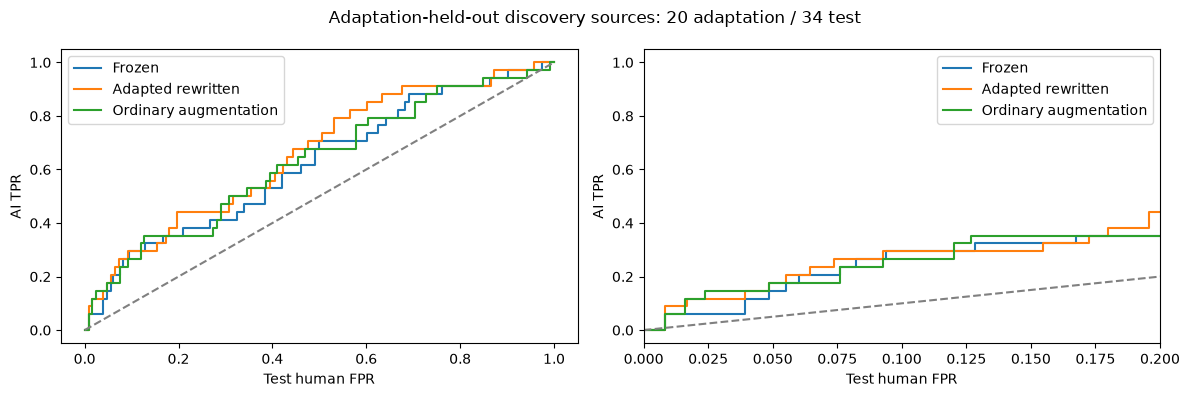

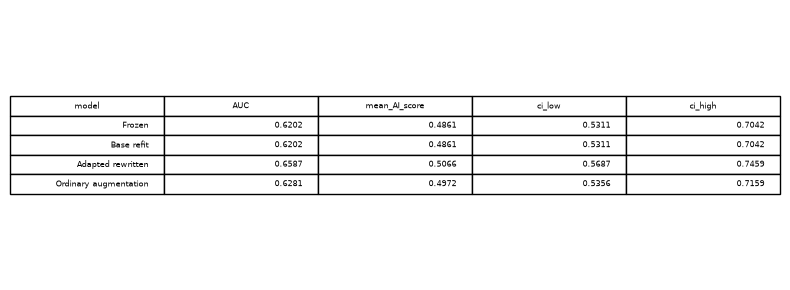

Saved ../results/causal/C02w_adaptive_camouflage_scored54_v1


,group,model,n_AI,mean_AI_score,AUC_fixed_overall_human_mix
0,historical_27,Frozen,19,0.461562,0.541941
1,historical_27,Base refit,19,0.461562,0.541941
2,historical_27,Adapted rewritten,19,0.477466,0.572212
3,historical_27,Ordinary augmentation,19,0.471221,0.549725
4,newly_completed_27,Frozen,15,0.517130,0.719277
5,newly_completed_27,Base refit,15,0.517130,0.719277
6,newly_completed_27,Adapted rewritten,15,0.543516,0.768289
7,newly_completed_27,Ordinary augmentation,15,0.530012,0.727440


In [5]:
A={};H={};CAL={};metrics=[];ops=[];curves=[];score_rows=[]
wc=hcal.weight.to_numpy(float);wh=htest.weight.to_numpy(float);n_test=int(ai_test.sum());assert n_test==34
for name,m in models.items():
    a=m.predict_proba(Xrewrite.loc[ai_test])[:,1];h=m.predict_proba(htest[model_features])[:,1];c=m.predict_proba(hcal[model_features])[:,1]
    A[name]=a;H[name]=h;CAL[name]=c
    cuts=np.r_[np.inf,np.unique(c)[::-1],-np.inf];cf=np.array([wc[c>t].sum() for t in cuts])
    for budget in BUDGETS:
        j=np.flatnonzero(cf<=budget+1e-12)[-1];t=cuts[j]
        ops.append(dict(model=name,requested_FPR=budget,threshold=t,calibration_FPR=cf[j],test_FPR=wh[h>t].sum(),TPR=(a>t).mean(),n_AI=n_test,n_human=len(h)))
    f,t,_=roc_curve(np.r_[np.zeros(len(h)),np.ones(len(a))],np.r_[h,a],sample_weight=np.r_[wh,np.ones(len(a))/len(a)],drop_intermediate=False)
    metrics.append(dict(model=name,AUC=auc(f,t),mean_AI_score=a.mean()))
    curves.extend(dict(model=name,FPR=x,TPR=y) for x,y in zip(f,t))
    score_rows.extend(dict(model=name,kind='AI',source_id=s,score=v) for s,v in zip(selection.loc[ai_test,'source_id'],a))
    score_rows.extend(dict(model=name,kind='human_test',source_id=s,score=v) for s,v in zip(htest.source_id,h))
    score_rows.extend(dict(model=name,kind='human_calibration',source_id=s,score=v) for s,v in zip(hcal.source_id,c))
metrics=pd.DataFrame(metrics);ops=pd.DataFrame(ops);curves=pd.DataFrame(curves)
pd.DataFrame(score_rows).to_csv(OUT/'scores.csv',index=False)
# Paired bootstrap: identical sampled AI/human IDs across all models, stratified by genre.
rng=np.random.default_rng(SEED);ag=selection.loc[ai_test,'domain'].to_numpy();hg=htest.domain.to_numpy()
def resample_groups(groups):
    return np.concatenate([rng.choice(np.flatnonzero(groups==g),size=sum(groups==g),replace=True) for g in sorted(set(groups))])
def weighted_auc(a,h,w):
    return roc_auc_score(np.r_[np.zeros(len(h)),np.ones(len(a))],np.r_[h,a],sample_weight=np.r_[w,np.ones(len(a))/len(a)])
boot={name:[] for name in models};boot_tpr={(name,b):[] for name in models for b in BUDGETS};boot_fpr={k:[] for k in boot_tpr}
for _ in range(B):
    ia=resample_groups(ag);ih=resample_groups(hg);w=wh[ih];w=w/w.sum()
    for name in models:
        a=A[name][ia];h=H[name][ih];boot[name].append(weighted_auc(a,h,w))
        for b in BUDGETS:
            cutoff=float(ops.loc[ops.model.eq(name)&ops.requested_FPR.eq(b),'threshold'].iloc[0])
            boot_tpr[name,b].append((a>cutoff).mean());boot_fpr[name,b].append(w[h>cutoff].sum())
for i,row in metrics.iterrows():metrics.loc[i,['ci_low','ci_high']]=np.quantile(boot[row.model],[.025,.975])
for i,row in ops.iterrows():
    ops.loc[i,['TPR_ci_low','TPR_ci_high']]=np.quantile(boot_tpr[row.model,row.requested_FPR],[.025,.975])
    ops.loc[i,['FPR_ci_low','FPR_ci_high']]=np.quantile(boot_fpr[row.model,row.requested_FPR],[.025,.975])
paired=[]
for baseline in ['Frozen','Ordinary augmentation']:
    delta=np.array(boot['Adapted rewritten'])-np.array(boot[baseline]);lo,hi=np.quantile(delta,[.025,.975])
    point=float(metrics.set_index('model').loc['Adapted rewritten','AUC']-metrics.set_index('model').loc[baseline,'AUC'])
    paired.append(dict(comparison='Adapted rewritten minus '+baseline,AUC_change=point,ci_low=lo,ci_high=hi))
metrics.to_csv(OUT/'ROC_AUC.csv',index=False);ops.to_csv(OUT/'TPR_at_calibrated_FPR.csv',index=False);curves.to_csv(OUT/'ROC_points.csv',index=False)
pd.DataFrame(paired).to_csv(OUT/'paired_AUC_changes.csv',index=False)
display(metrics);display(ops);display(pd.DataFrame(paired))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for name in models:
    if name=='Base refit':continue
    r=curves.loc[curves.model.eq(name)]
    for ax in axes:ax.step(r.FPR,r.TPR,where='post',label=name)
for ax in axes:ax.plot([0,1],[0,1],'--',color='gray');ax.set(xlabel='Test human FPR',ylabel='AI TPR');ax.legend()
axes[1].set_xlim(0,.2);fig.suptitle('Adaptation-held-out discovery sources: 20 adaptation / 34 test');fig.tight_layout()
for ext in ['png','pdf']:_export_figure(fig,OUT/f'adaptive_ROC.{ext}',dpi=300,bbox_inches='tight')
plt.show()
fig,ax=plt.subplots(figsize=(8,3));ax.axis('off')
t=metrics.copy();t=t.round(4);ax.table(cellText=t.values,colLabels=t.columns,loc='center');fig.tight_layout()
for ext in ['png','pdf']:_export_figure(fig,OUT/f'adaptive_AUC_table.{ext}',dpi=300,bbox_inches='tight')
plt.show()
print('Saved',OUT)

# Coverage-policy subgroup diagnostics: do not obscure historical vs completed cases.
subgroups=np.array(['historical_27' if cid in known else 'newly_completed_27' for cid in selection.loc[ai_test,'case_id']])
subrows=[]
for group in sorted(set(subgroups)):
    mask=subgroups==group
    for name in models:
        subrows.append(dict(group=group,model=name,n_AI=int(mask.sum()),mean_AI_score=float(A[name][mask].mean()),
            AUC_fixed_overall_human_mix=weighted_auc(A[name][mask],H[name],wh)))
pd.DataFrame(subrows).to_csv(OUT/'coverage_subgroup_diagnostic.csv',index=False)
display(pd.DataFrame(subrows))
